# 03 — Detection is not identification

**Draft tutorial · 14 September 2026.** [Notebook 02](../tutorials/02_from_coin_to_quantum_sensor.ipynb)
showed why a dark-extremum readout notices lost contrast. It left a harder question:
*what made the contrast fall?*

A fluctuating field can blur phase. Ordinary deterioration of the sensor's coherence can also
blur phase. An alarm against the old calibration does not choose between those explanations.
This notebook first constructs their ambiguity at one interrogation time, then asks what a scan
across interrogation times can resolve.

The calculation imports roadmap E's functions from `analysis/lib`. It uses the
**finite-window OU phase variance** for marginal outcome probabilities, and asks about contrast
curves only. It does not simulate their temporal likelihood or resolve roadmap F.

You should leave able to distinguish no information from very little information, and to explain
why the answer depends on what baseline drift is allowed.


In [1]:
import math, os, sys, io
from pathlib import Path

import numpy as np

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# Import the project's tested functions rather than restating the formulas here.
# Normally the notebook is opened from tutorials/, so walking up finds the repository.
# SID_ROOT overrides that, which is how the test executes it from a temporary directory.
ROOT = Path(os.environ["SID_ROOT"]) if os.environ.get("SID_ROOT") else Path.cwd()
while not (ROOT / "analysis" / "lib").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "analysis" / "lib").is_dir():
    raise RuntimeError("run this notebook from inside the repository, or set SID_ROOT")
sys.path.insert(0, str(ROOT / "analysis" / "lib"))
from sid_lib import DB, INK, SEA, SIG, STONE, PARCH
from sid_identifiability import (G, TAU_OVER_T2, s2_of, pd,
                                 dephased_probability, class_a_margin, information_at)

plt.rcParams.update({"font.family": "serif", "figure.dpi": 130,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5})


# sid_lib selects the Agg backend on import, disabling the inline formatter, so figures are
# rendered explicitly. IPython is optional: without it the notebook still runs top to bottom
# (that is how the test executes it), it simply draws nothing.
try:
    from IPython.display import Image, display
    _INLINE = True
except ImportError:
    _INLINE = False

def show(fig):
    if _INLINE:
        buf = io.BytesIO(); fig.savefig(buf, format="png", bbox_inches="tight")
        display(Image(data=buf.getvalue()))
    plt.close(fig)

# Lines prefixed [env] record which stack executed the notebook. They are provenance, not
# results, and are excluded when the tests compare fresh output against committed output --
# they are *expected* to differ between interpreters.
print("[env] project root:", ROOT.name)
import scipy
print("[env] python", ".".join(map(str, sys.version_info[:3])), "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)


[env] project root: signals-in-darkness
[env] python 3.13.7 | numpy 2.4.4 | scipy 1.17.1 | matplotlib 3.10.8


## 1. Two causes, the same coin

Use dimensionless times $u=\tau/T_2$ and $v=\tau_c/T_2$. The nominal dephasing exponent is $u$;
a changed baseline has exponent $\gamma u$, where $\gamma=\Gamma/\widehat\Gamma$.
The initial contrast is $C_0$, before this time-dependent decay.

The dark-outcome probability is $(1-C_{\rm eff})/2$. Under additional OU phase variance
$s^2(u,v)$, the effective contrast is $C_0\exp[-\gamma u-s^2(u,v)/2]$.
At a single chosen time, a larger baseline dephasing rate can absorb that additional exponent.
The two causes then give **the same one-shot Bernoulli law**.

This first construction deliberately allows any baseline rate. The calibration band that might
exclude it comes in section 3. Equal marginals do not assert that the full time-ordered records
are identical.


C0 = 0.4; tau/T2 = 1.0; tau_c/T2 = 1.0; g sigma_x T2 = 0.5
Nominal dark probability:          0.42642411
With frequency noise:             0.43288903
With changed baseline alone:      0.43288903
Mimicking baseline Gamma/Gamma_hat = 1.09196986
D(signal || nominal) = 8.533232e-05 nats/shot
D(signal || mimic)   = 0.000000e+00 nats/shot


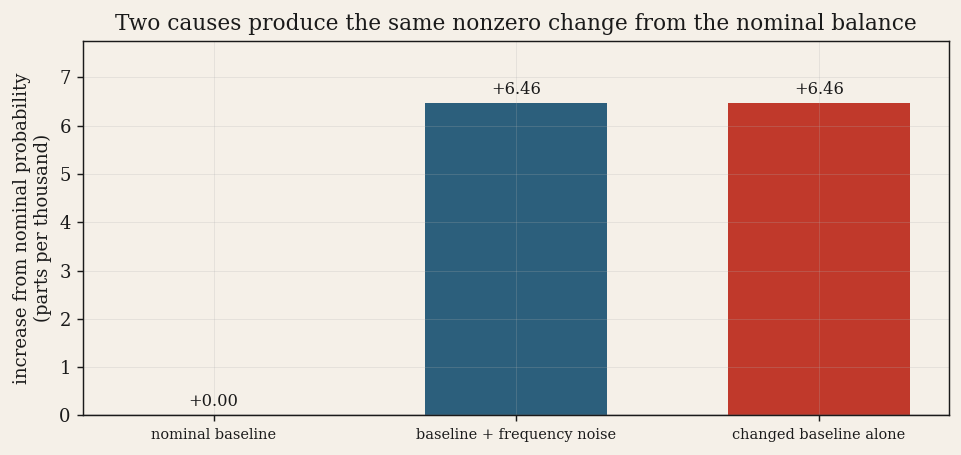

In [2]:
C0 = 0.4
v_example = 1.0
u_match = 1.0
variance_match = s2_of(u_match, v_example)
gamma_mimic = 1.0 + variance_match/(2*u_match)
p_nominal = dephased_probability(C0, u_match)
p_signal = dephased_probability(C0, u_match, phase_variance=variance_match)
p_mimic = dephased_probability(C0, u_match, gamma=gamma_mimic)
print(f"C0 = {C0}; tau/T2 = {u_match}; tau_c/T2 = {v_example}; g sigma_x T2 = {G}")
print(f"Nominal dark probability:          {p_nominal:.8f}")
print(f"With frequency noise:             {p_signal:.8f}")
print(f"With changed baseline alone:      {p_mimic:.8f}")
print(f"Mimicking baseline Gamma/Gamma_hat = {gamma_mimic:.8f}")
print(f"D(signal || nominal) = {DB(p_signal, p_nominal):.6e} nats/shot")
print(f"D(signal || mimic)   = {DB(p_signal, p_mimic):.6e} nats/shot")
assert abs(p_signal-p_mimic) < 1e-14
fig, ax = plt.subplots(figsize=(7.5, 3.6), facecolor=PARCH)
ax.set_facecolor(PARCH)
changes = np.array([p_nominal, p_signal, p_mimic]) - p_nominal
ax.bar(["nominal baseline", "baseline + frequency noise", "changed baseline alone"],
       1000*changes, color=[STONE, SEA, SIG], width=0.6)
ax.axhline(0, color=STONE, lw=0.8)
for index, change in enumerate(changes):
    ax.annotate(f"{1000*change:+.2f}", (index, 1000*change),
                xytext=(0, 5), textcoords="offset points", ha="center", fontsize=9)
ax.set(ylabel="increase from nominal probability\n(parts per thousand)", ylim=(0, max(1, 1200*changes.max())),
       title="Two causes produce the same nonzero change from the nominal balance")
ax.tick_params(axis="x", labelsize=8)
fig.tight_layout(); show(fig)


> **worked example** — the signal is distinguishable from the nominal coin but not from
> this fitted baseline using its one-shot balance at the chosen time. More repetitions improve
> the probability estimate; they do not break an exact equality of those marginal probabilities.

## 2. Change the interrogation time, keep the rival explanation fixed

Once the changed baseline has been fitted at one time, it must explain all the other times with
that **same** rate if it belongs to the exponential, or Markov-parametric, family. The OU exponent
curves with interrogation time. A single straight-line exponent need not follow it.

The plot shows the rival matched at $u=1$, not the best fit to the entire scan. We compute that
more conservative comparison in section 3.


Largest absolute probability mismatch on the scan: 2.551804e-03


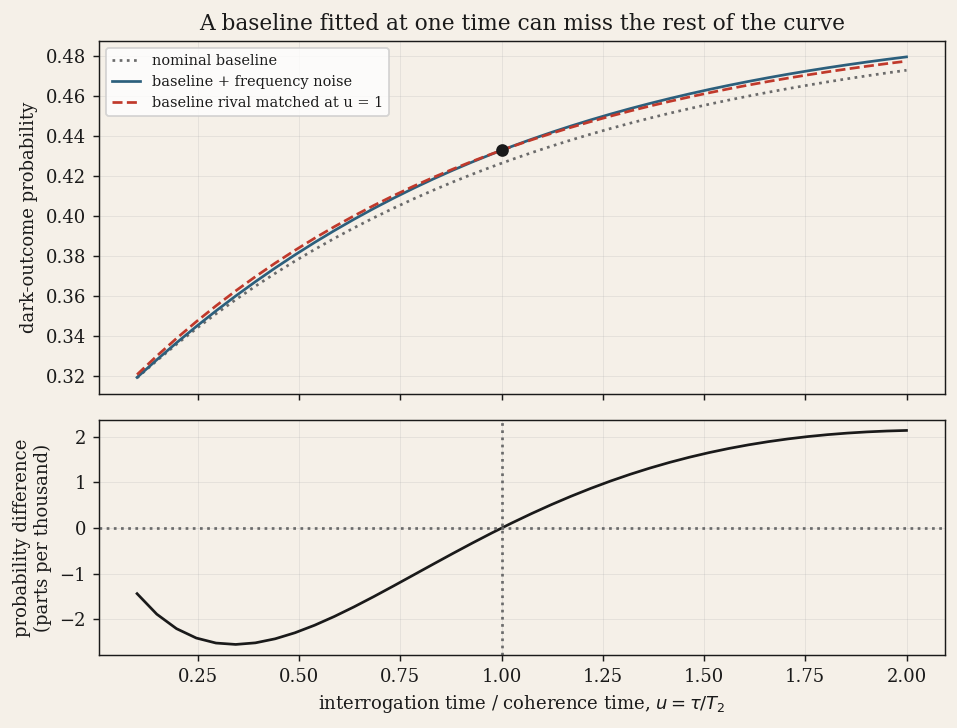

In [3]:
u_grid = TAU_OVER_T2
variances = np.array([s2_of(u, v_example) for u in u_grid])
p_curve = dephased_probability(C0, u_grid, phase_variance=variances)
p_rival = dephased_probability(C0, u_grid, gamma=gamma_mimic)
p_base = dephased_probability(C0, u_grid)
fig, axes = plt.subplots(2, 1, figsize=(7.5, 5.7), facecolor=PARCH, sharex=True,
                         gridspec_kw={"height_ratios": [1.5, 1]})
for ax in axes: ax.set_facecolor(PARCH)
axes[0].plot(u_grid, p_base, color=STONE, ls=":", label="nominal baseline")
axes[0].plot(u_grid, p_curve, color=SEA, label="baseline + frequency noise")
axes[0].plot(u_grid, p_rival, color=SIG, ls="--", label="baseline rival matched at u = 1")
axes[0].scatter([u_match], [p_signal], color=INK, zorder=4)
axes[0].set(ylabel="dark-outcome probability", title="A baseline fitted at one time can miss the rest of the curve")
axes[0].legend(fontsize=8)
axes[1].plot(u_grid, 1000*(p_curve-p_rival), color=INK)
axes[1].axhline(0, color=STONE, ls=":")
axes[1].axvline(u_match, color=STONE, ls=":")
axes[1].set(xlabel=r"interrogation time / coherence time, $u=\tau/T_2$",
            ylabel="probability difference\n(parts per thousand)")
print(f"Largest absolute probability mismatch on the scan: {np.max(np.abs(p_curve-p_rival)):.6e}")
fig.tight_layout(); show(fig)


> **worked example** — this scan rejects the particular rival matched at one time at the
> level of exact marginal probabilities. Finite data still have sampling uncertainty, and another
> allowed baseline may fit better. Seeing two drawn curves separate is not a calibrated alarm.

## 3. State which baseline changes are allowed

The reference calibration is $\widehat\chi(u)=u$, with fractional uncertainty $\eta_0$.
The project compares two nested nuisance classes:

| baseline family | what is allowed across the scan | consequence |
|---|---|---|
| A: pointwise band | choose any $\chi(u)$ within $u\pm\eta_0u$ independently at each time | can imitate more shapes |
| B: Markov-parametric | one rate $\gamma$ in $[1-\eta_0,1+\eta_0]$ for the whole scan | must keep one exponential shape |

Both the signal-present and signal-absent explanations may choose their own allowed baseline.
The worst-case comparison therefore uses the full width between the two band edges. At a given
$u$, class A separates only when $s^2(u,v)/2>2\eta_0u$. If the intervals overlap at every sampled
$u$, the worst-case marginal information is exactly zero. This is an ambiguity **within the
stated nuisance model and contrast-scan experiment**, not a ban on every possible measurement.

`information_at` recomputes three quantities, all averaged over the same equally allocated scan:

- `I_unc`: information against the nominal baseline, assuming it is known exactly;
- `I_A`: worst-case retained information for the pointwise band;
- `I_B`: best-of-candidates estimate for the shape-constrained baseline pair.

The class-B search includes three named starts, a deterministic grid and its local polish. Its
minimum is a numerical estimate, **not a certified global infimum**. Every candidate lies
inside class B, so the displayed $I_B$ values are **upper bounds on the class-B infimum**:
a missed lower candidate could only make $I_B$ smaller. A positive candidate value alone does
not prove that the infimum is positive.

Class B is contained in class A. Restricting the rival family cannot reduce the true retained
information, so $I_A\leq I_{B,\mathrm{true}}\leq I_B$. These are different directions:
$I_A$ bounds the class-B infimum from below, while a feasible candidate bounds it from above.
The grid matters: the
[note that closed E](../notes/2026-09-07-note-16-E-closure.md) records cases where all named starts
agreed closely and still missed a lower candidate.


C0 = 0.4; calibration eta0 = 0.02; 40 equally weighted interrogation times
Information is PER SHOT, with no dead time priced.
 tau_c/T2        I_unc    I_A/I_unc    I_B/I_unc   A passing
     0.05  1.10665e-06  0.00000e+00  2.22489e-03      0/40
     0.20  1.20121e-05  3.64818e-03  2.26220e-02     21/40
     1.00  6.87829e-05  3.88016e-01  3.88968e-01     34/40
     5.00  1.20973e-04  5.30630e-01  5.31087e-01     35/40


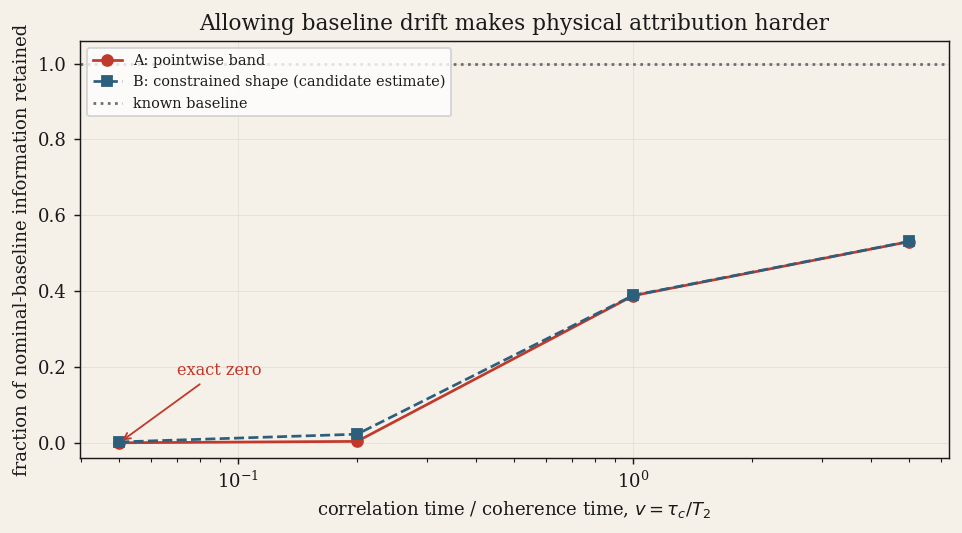

In [4]:
ETA0 = 0.02
V_SCAN = (0.05, 0.2, 1.0, 5.0)
rows = [information_at(C0, ETA0, v) for v in V_SCAN]
print(f"C0 = {C0}; calibration eta0 = {ETA0}; {len(TAU_OVER_T2)} equally weighted interrogation times")
print("Information is PER SHOT, with no dead time priced.")
print(f"{'tau_c/T2':>9} {'I_unc':>12} {'I_A/I_unc':>12} {'I_B/I_unc':>12} {'A passing':>11}")
for row in rows:
    print(f"{row['tau_c_over_T2']:9.2f} {row['I_unc']:12.5e} "
          f"{row['I_A']/row['I_unc']:12.5e} {row['I_B']/row['I_unc']:12.5e} "
          f"{row['class_A_points_passing']:6d}/{row['class_A_points_total']}")
fig, ax = plt.subplots(figsize=(7.5, 4.2), facecolor=PARCH)
ax.set_facecolor(PARCH)
a_fraction = np.array([r['I_A']/r['I_unc'] for r in rows])
b_fraction = np.array([r['I_B']/r['I_unc'] for r in rows])
# Exact zero stays at zero on a linear axis; it is never replaced by a log-axis floor.
ax.plot(V_SCAN, a_fraction, 'o-', color=SIG, label="A: pointwise band")
ax.plot(V_SCAN, b_fraction, 's--', color=SEA, label="B: constrained shape (candidate estimate)")
ax.axhline(1, color=STONE, ls=":", label="known baseline")
ax.set(xscale="log", xlabel=r"correlation time / coherence time, $v=\tau_c/T_2$",
       ylabel="fraction of nominal-baseline information retained", ylim=(-0.04, 1.06),
       title="Allowing baseline drift makes physical attribution harder")
ax.annotate("exact zero", xy=(V_SCAN[0], a_fraction[0]), xytext=(0.07, 0.18),
            arrowprops={"arrowstyle": "->", "color": SIG}, color=SIG, fontsize=9)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); show(fig)


> **worked example** — at the shortest correlation time, the pointwise class can absorb
> the whole marginal signature on this scan, while the constrained family's best candidate
> gives a small upper bound on its retained information. At the next point, the pointwise
> information is small but nonzero.
> The table, rather than a plotting floor, distinguishes those cases.

> **C26 — result** — the settled ledger makes that distinction explicit. The pointwise band
> retains zero at $\tau_c/T_2=0.05$ on the committed grid, but at $\tau_c/T_2=0.2$ and tight
> calibration it retains a small nonzero fraction. Class B's values remain best-of-candidates
> estimates, with the upper-bound direction explained above. The claim is per shot and does
> not price dead time.

> **C13 — withdrawn** — the earlier claim treated the boundary case as exactly zero.
> It was withdrawn and replaced by C26 because impossible and difficult are different statements.

## 4. Why the fast-noise criterion is a limit, not a substitute for the scan

For correlation time short compared with interrogation time, the extra exponent is approximately
$\Delta\Gamma_\phi\tau$. In these units
$\Delta\Gamma_\phi/\widehat\Gamma=G^2v$, with $G=g\sigma_xT_2$.
The band-separation criterion becomes $G^2v>2\eta_0$.

At finite positive $u/v$, the exact OU exponent lies strictly below its fast-noise limit.
A fast-noise ratio $G^2v/(2\eta_0)>1$ is therefore **necessary but not sufficient** for separation
at a chosen interrogation time, or anywhere on a finite scan. Compare the exact exponent's excess
over the band width at
the boundary case for tight and looser calibration. The dimensionless fast-noise ratios printed
below come from the same research helper as the table.


eta0 = 0.02: fast-noise ratio = 1.2500; exact separation at 21 of 40 times
eta0 = 0.05: fast-noise ratio = 0.5000; exact separation at 0 of 40 times


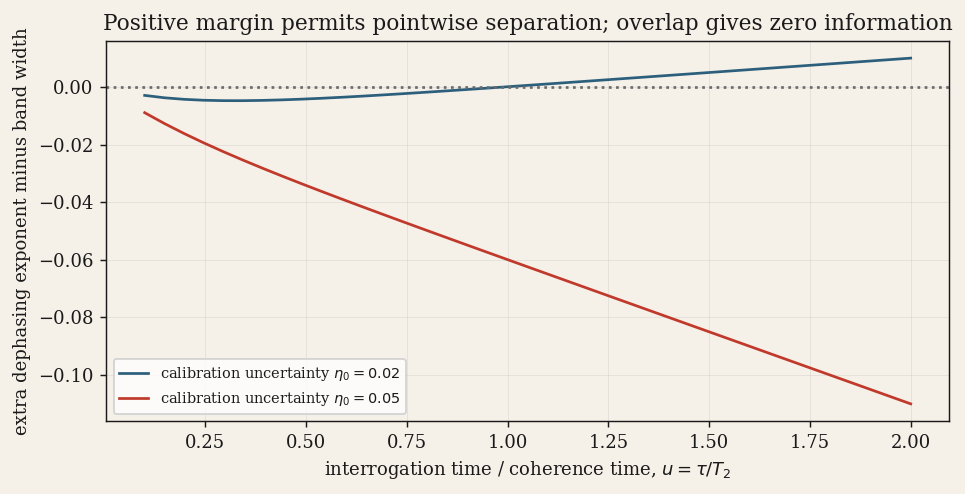

In [5]:
v_boundary = 0.2
eta_values = (0.02, 0.05)
fig, ax = plt.subplots(figsize=(7.5, 3.9), facecolor=PARCH)
ax.set_facecolor(PARCH)
for eta, color in zip(eta_values, [SEA, SIG]):
    result = information_at(C0, eta, v_boundary)
    # Positive means that the allowed probability intervals no longer overlap at this time.
    margin = np.array([class_a_margin(u, s2_of(u, v_boundary), eta) for u in u_grid])
    ax.plot(u_grid, margin, color=color, label=rf"calibration uncertainty $\eta_0={eta}$")
    print(f"eta0 = {eta:.2f}: fast-noise ratio = {result['DeltaGamma_over_2eta0_Gamma_hat']:.4f}; "
          f"exact separation at {result['class_A_points_passing']} of {len(u_grid)} times")
ax.axhline(0, color=STONE, ls=":")
ax.set(xlabel=r"interrogation time / coherence time, $u=\tau/T_2$",
       ylabel="extra dephasing exponent minus band width",
       title="Positive margin permits pointwise separation; overlap gives zero information")
ax.legend(fontsize=8)
fig.tight_layout(); show(fig)


> **worked example** — tightening the calibration band changes whether the contrast scan
> can separate explanations. The fast-noise ratio above one is necessary but not sufficient:
> even with the tight band it exceeds one while only part of the finite scan passes the exact
> condition. The looser band fails throughout.

## Try it, then decide what the alarm means

1. Change `C0` to `0.5` and run the notebook again. Compare the absolute information with the
   fraction retained. Why are they different ways to describe sensitivity?
2. In section 3, change `ETA0` to `0.05`. Which boundary row loses its pointwise information?
3. Return to the one-time mimic. Is its fitted rate inside either of the calibration bands used
   later? What additional assumption made that first ambiguity possible?
4. Explain why mid-fringe correlations might help distinguish causes, and why correlated
   technical noise would itself need a model before that interpretation could be trusted.

A defensible interpretation proceeds in stages: detect departure from the calibrated model,
test the candidate cause against the allowed baseline family, then report whether the measured
features separate them. If they do not, “additional dephasing detected” says what the contrast
evidence supports.

The four notebooks now connect toss counts, temporal ordering, readout choice and physical
attribution. The [claim ledger](../ledgers/status.yaml) carries the research conclusions; the
[roadmap](../ledgers/roadmap.yaml) records the correlated-residual and finite-window likelihood
checks still open. These tutorials are views of that work, not new evidence or hardware results.
